In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
try:
    df = pd.read_csv('heartrate_seconds_merged.csv')
    X_raw = np.linspace(0, 5, len(df))
    Y = df['Value'].values[:len(X_raw)]
except:
    np.random.seed(42)
    X_raw = np.linspace(0, 5, 100)
    Y = 3 * (X_raw ** 3) - 5 * (X_raw ** 2) + 2 * X_raw + np.random.normal(0, 4, 100)

def build_poly_features(X, degree=3):
    X_poly = np.column_stack([X**i for i in range(1, degree + 1)])
    X_poly = (X_poly - np.mean(X_poly, axis=0)) / np.std(X_poly, axis=0)
    return np.c_[np.ones(X_poly.shape[0]), X_poly] # إضافة عمود الـ Bias

X_poly = build_poly_features(X_raw, degree=3)
print("Data shape (X_poly):", X_poly.shape)

Data shape (X_poly): (100, 4)


In [4]:
def compute_loss(Y_true, Y_pred):
    m = len(Y_true)
    return (1 / (2 * m)) * np.sum((Y_pred - Y_true) ** 2)

print("Loss function (MSE) defined successfully.")

Loss function (MSE) defined successfully.


In [5]:
def batch_gradient_descent_momentum(X, Y, learning_rate=0.03, beta=0.9, epochs=200):
    m, n = X.shape
    weights = np.zeros(n)
    velocity = np.zeros(n)  # متجه الـ Momentum المطلوب
    
    loss_history = []
    momentum_history = []
    
    for epoch in range(epochs):
        predictions = np.dot(X, weights)
        error = predictions - Y
        gradient = (1 / m) * np.dot(X.T, error)
        
        # تطبيق معادلة الـ Momentum (Velocity update)
        velocity = beta * velocity + learning_rate * gradient
        weights -= velocity
        
        # حساب تخزين الـ Loss والـ Momentum
        loss = compute_loss(Y, predictions)
        loss_history.append(loss)
        momentum_history.append(np.mean(np.abs(velocity)))
        
    return weights, loss_history, momentum_history

# تشغيل الخوارزمية بمعدل تعلم وأطر زمنية محددة
learning_rate = 0.03
epochs = 200
optimal_weights, losses, momentum_vals = batch_gradient_descent_momentum(X_poly, Y, learning_rate, beta=0.9, epochs=epochs)

print("="*50)
print("--- Gradient Descent with Momentum Results ---")
print("Final Weights:", optimal_weights)
print("Final MSE Loss:", losses[-1])
print("="*50)

--- Gradient Descent with Momentum Results ---
Final Weights: [ 57.40560777 -23.27406585  27.65425323  67.57127525]
Final MSE Loss: 8.086461901073008


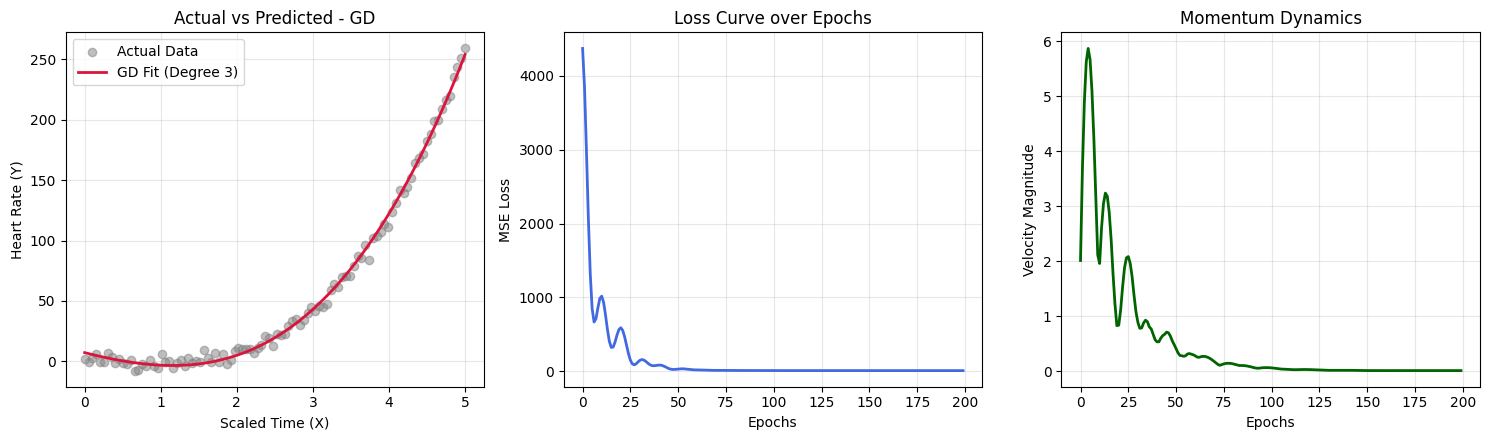

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Actual vs Predicted (Polynomial Fit)
axes[0].scatter(X_raw, Y, color='gray', alpha=0.5, label='Actual Data')
axes[0].plot(X_raw, np.dot(X_poly, optimal_weights), color='crimson', linewidth=2, label='GD Fit (Degree 3)')
axes[0].set_xlabel('Scaled Time (X)')
axes[0].set_ylabel('Heart Rate (Y)')
axes[0].set_title('Actual vs Predicted - GD')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Loss Curve
axes[1].plot(losses, color='royalblue', linewidth=2)
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('MSE Loss')
axes[1].set_title('Loss Curve over Epochs')
axes[1].grid(True, alpha=0.3)

# 3. Momentum Evolution (حركة الـ Momentum)
axes[2].plot(momentum_vals, color='darkgreen', linewidth=2)
axes[2].set_xlabel('Epochs')
axes[2].set_ylabel('Velocity Magnitude')
axes[2].set_title('Momentum Dynamics')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()